# Movie Genre Analysis
## Summary
Analysis of the supplied `imdb_movies.csv`. Findings are calculated in the result cells. The source contains 10,866 rows; one exact duplicate is removed. Genre memberships overlap. Reported financial differences are not net profit.

Verified highlights: Drama has 4,760 movies; Comedy 3,793; Thriller 2,907. Drama has 21 high-rated movies out of 2,057 with at least 50 votes and a known rating. Only 3,854 movies have positive budget and revenue. These results describe the uploaded historical sample, not today's market.


## Context and methods
Questions: which genres appear most often; how do budgets, revenues, popularity, and high-rating prevalence vary; and how are ratings, popularity, and financial measures associated?

### Key assumptions
- Use unique `id` or `imdb_id`, not title, to identify movies. Stop on conflicting IDs.
- Movies can belong to multiple genres. Genre counts overlap and do not form a partition; do not sum genre budgets/revenues as a market total.
- Exclude nonpositive budget/revenue from financial comparisons under an explicit unknown/unusable-value policy. Do not silently include zeros in financial averages.
- Financial amounts are not inflation-adjusted. `revenue - budget` is a reported gross surplus proxy, not net profit (distribution, marketing, and other costs are absent).
- High rating means vote average >=8 and at least 50 votes, an analytical threshold rather than a universal quality definition.
- Associations are descriptive, not causal hypothesis tests.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
OUT = ROOT / 'outputs'
OUT.mkdir(exist_ok=True)
pd.set_option('display.max_columns', 12)
pd.set_option('display.float_format', lambda value: f'{value:,.3f}')
plt.rcParams.update({'figure.figsize': (10, 5), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
BLUE = '#24577A'


## Data checks


In [2]:
source = ROOT / 'data' / 'imdb_movies.csv'
if not source.exists():
    raise FileNotFoundError(f'Missing original movie dataset: {source}')
raw = pd.read_csv(source)
required = ['original_title','genres','budget','revenue','popularity','vote_count','vote_average','release_year']
assert not (set(required)-set(raw)), 'Movie dataset schema differs from the submitted notebook'
movies = raw.drop_duplicates().copy()
key = 'id' if 'id' in movies else 'imdb_id' if 'imdb_id' in movies else None
if key is None: raise ValueError('A stable movie ID is required; titles are not unique identifiers')
assert movies[key].notna().all(), 'Investigate missing IDs'
assert not movies[key].duplicated().any(), 'Resolve conflicting movie IDs before analysis'
movies = movies.rename(columns={key:'movie_id'})
num = ['budget','revenue','popularity','vote_count','vote_average','release_year']
for col in num:
    converted = pd.to_numeric(movies[col],errors='coerce')
    assert not (movies[col].notna() & converted.isna()).any(), f'Invalid numeric values: {col}'
    movies[col] = converted
assert movies['vote_average'].dropna().between(0,10).all()
assert movies['vote_count'].dropna().ge(0).all()
valid_genre = movies['genres'].notna() & movies['genres'].fillna('').str.strip().ne('')
financial = movies['budget'].gt(0) & movies['revenue'].gt(0)
quality = pd.Series({'source_rows':len(raw),'exact_duplicates_removed':len(raw)-len(movies),
    'unique_movies':len(movies),'missing_genre_movies':int((~valid_genre).sum()),
    'usable_financial_movies':int(financial.sum())})
display(quality.to_frame('count'))
quality.to_csv(OUT/'quality_checks.csv')
movies['gross_surplus_proxy'] = (movies['revenue']-movies['budget']).where(financial)
movies['reported_budget'] = movies['budget'].where(financial)
movies['reported_revenue'] = movies['revenue'].where(financial)


,count
source_rows,10866
exact_duplicates_removed,1
unique_movies,10865
missing_genre_movies,23
usable_financial_movies,3854


## Genre comparisons


,movies,mean_popularity,financial_movies,mean_budget,median_budget,mean_revenue,median_revenue,median_surplus
genre,,,,,,,,
Drama,4760,0.591,1756,"28,052,383.046","20,000,000.000","74,327,265.890","32,854,660.500","11,662,805.500"
Comedy,3793,0.593,1358,"33,109,057.145","23,000,000.000","97,336,565.783","46,577,200.000","21,552,781.500"
Thriller,2907,0.742,1204,"37,294,600.169","25,000,000.000","97,740,462.823","44,131,168.500","18,515,031.500"
Action,2384,0.926,1085,"56,440,442.820","40,000,000.000","156,577,156.787","72,108,608.000","30,795,814.000"
Romance,1712,0.592,667,"27,275,334.714","20,000,000.000","85,748,008.024","37,317,558.000","17,126,295.000"
Horror,1637,0.465,463,"18,566,308.320","11,000,000.000","57,287,803.583","29,907,685.000","16,370,001.000"
Adventure,1471,1.154,749,"69,938,913.215","50,000,000.000","218,291,850.850","104,478,416.000","51,000,000.000"
Crime,1354,0.745,651,"33,035,741.106","25,000,000.000","84,143,092.410","41,610,884.000","16,282,766.000"
Family,1231,0.787,425,"62,479,155.609","48,000,000.000","203,153,546.741","109,578,115.000","57,634,409.000"


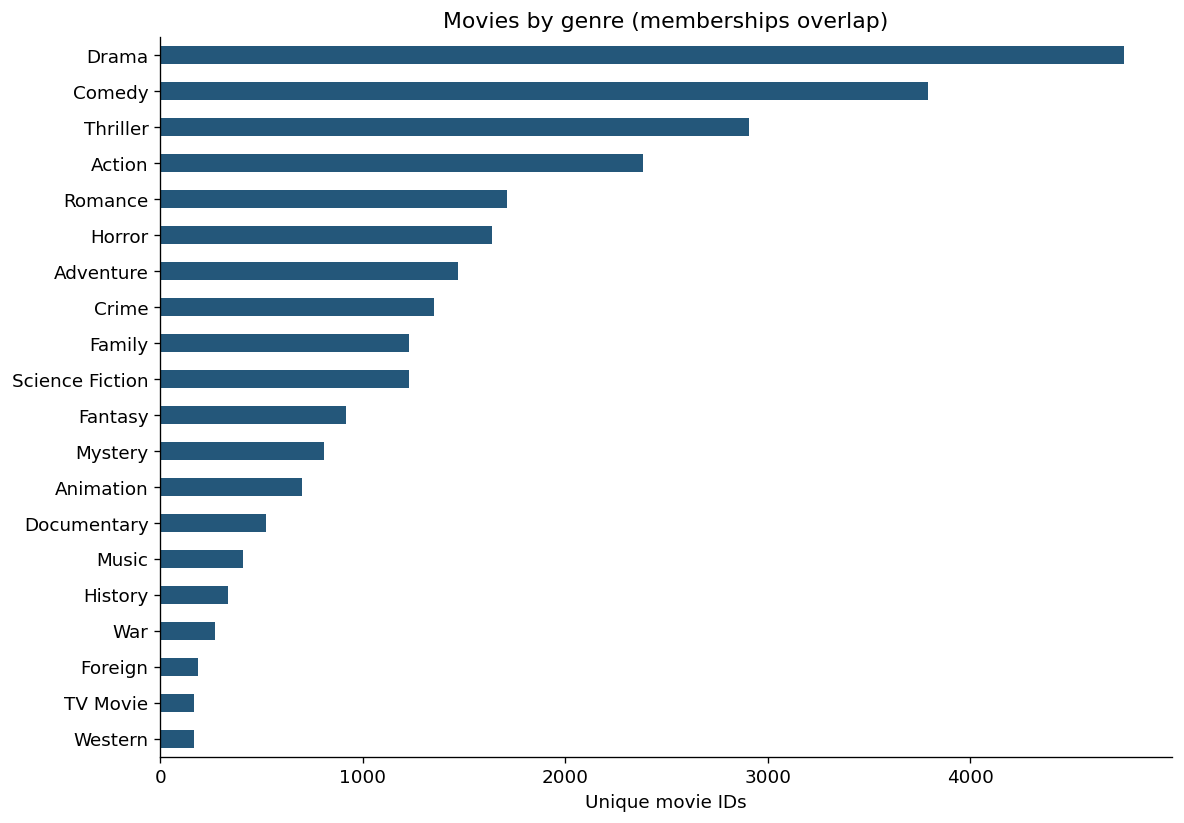

In [3]:
genres = movies.loc[valid_genre].copy()
genres['genre'] = genres['genres'].str.split('|')
genres = genres.explode('genre')
genres['genre'] = genres['genre'].str.strip()
genres = genres.loc[genres['genre'].ne('')].drop_duplicates(['movie_id','genre'])
genre_summary = genres.groupby('genre').agg(
    movies=('movie_id','nunique'), mean_popularity=('popularity','mean'),
    financial_movies=('gross_surplus_proxy','count'), mean_budget=('reported_budget','mean'),
    median_budget=('reported_budget','median'), mean_revenue=('reported_revenue','mean'),
    median_revenue=('reported_revenue','median'), median_surplus=('gross_surplus_proxy','median'))
display(genre_summary.sort_values('movies',ascending=False))
genre_summary.to_csv(OUT/'genre_summary.csv')
fig,ax=plt.subplots(figsize=(10,7))
genre_summary['movies'].sort_values().plot.barh(ax=ax,color=BLUE)
ax.set(title='Movies by genre (memberships overlap)',xlabel='Unique movie IDs',ylabel='')
fig.tight_layout();fig.savefig(OUT/'genre_counts.png',dpi=160,bbox_inches='tight');plt.show()


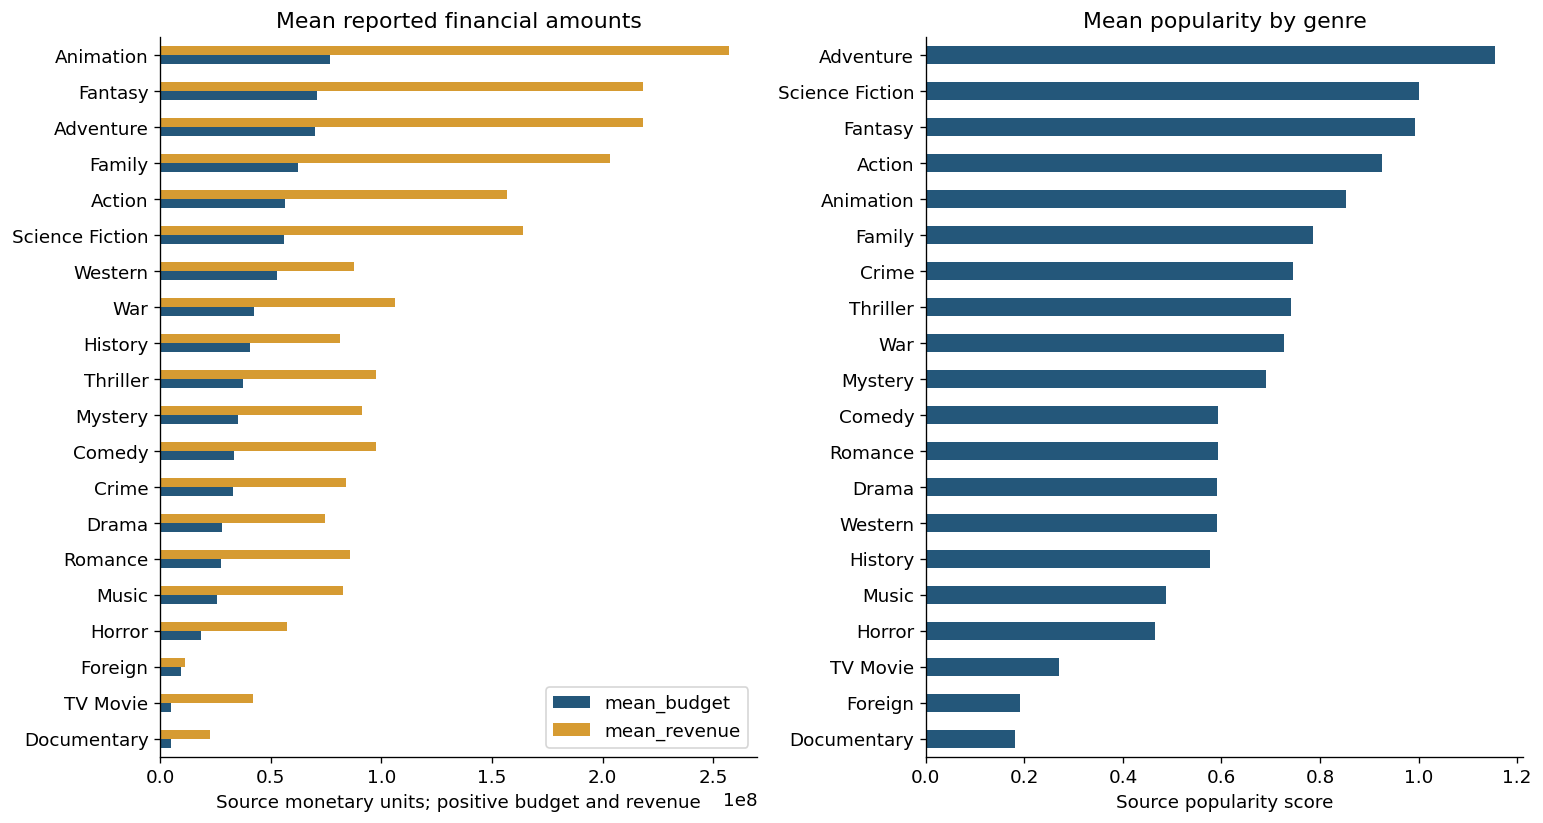

In [4]:
fig,axes=plt.subplots(1,2,figsize=(13,7))
genre_summary[['mean_budget','mean_revenue']].sort_values('mean_budget').plot.barh(ax=axes[0],color=[BLUE,'#D69B32'])
axes[0].set(title='Mean reported financial amounts',xlabel='Source monetary units; positive budget and revenue',ylabel='')
genre_summary['mean_popularity'].sort_values().plot.barh(ax=axes[1],color=BLUE)
axes[1].set(title='Mean popularity by genre',xlabel='Source popularity score',ylabel='')
fig.tight_layout();fig.savefig(OUT/'genre_finance_popularity.png',dpi=160,bbox_inches='tight');plt.show()


### High ratings: count movies, not distinct rating values


,eligible_movies,high_rated_movies,high_rating_rate
genre,,,
Drama,2057,21,0.010
Crime,755,10,0.013
Documentary,87,7,0.080
Thriller,1459,6,0.004
Family,615,5,0.008
Animation,367,5,0.014
Adventure,890,4,0.004
Action,1239,3,0.002
Comedy,1742,3,0.002


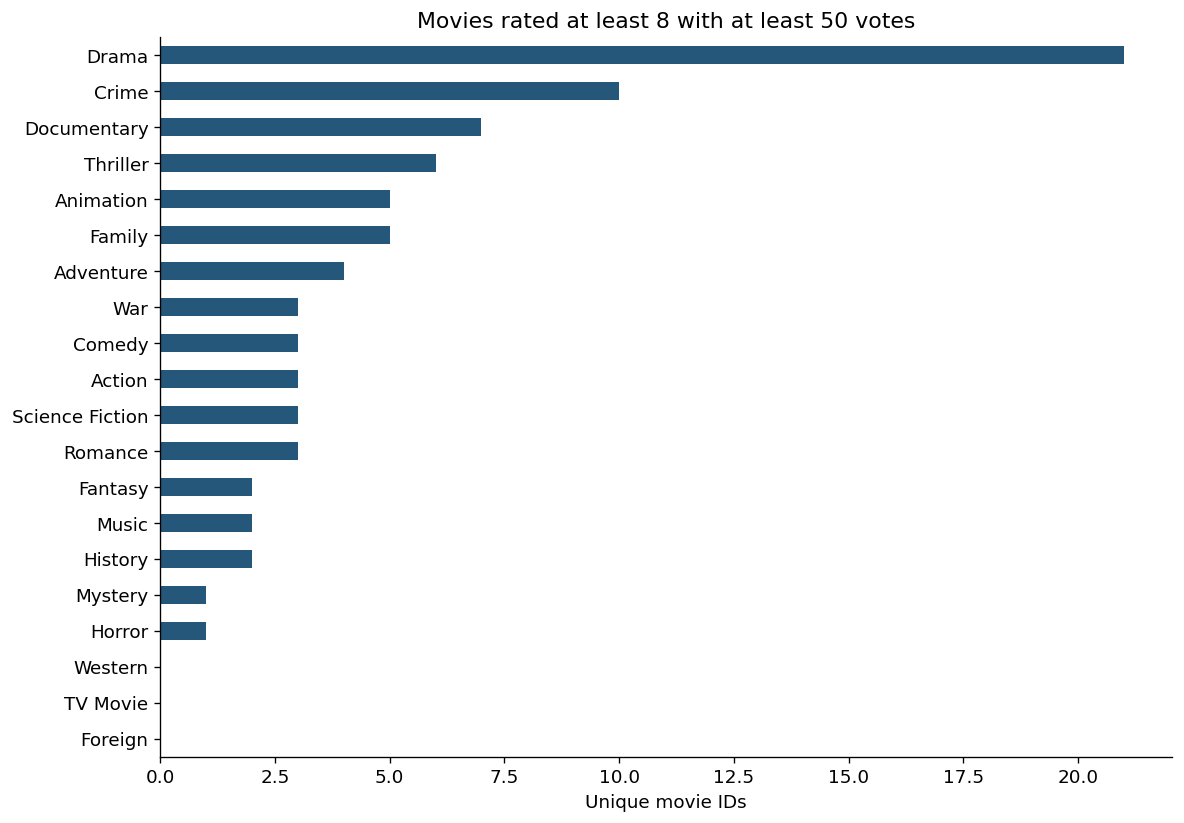

In [5]:
MIN_VOTES=50
qualified = genres.loc[genres['vote_count'].ge(MIN_VOTES) & genres['vote_average'].notna()]
eligible = qualified.groupby('genre')['movie_id'].nunique()
high = qualified.loc[qualified['vote_average'].ge(8)].groupby('genre')['movie_id'].nunique()
ratings = eligible.rename('eligible_movies').to_frame()
ratings['high_rated_movies'] = high.reindex(ratings.index,fill_value=0)
ratings['high_rating_rate'] = ratings['high_rated_movies']/ratings['eligible_movies']
assert ratings['high_rated_movies'].le(ratings['eligible_movies']).all()
display(ratings.sort_values('high_rated_movies',ascending=False))
ratings.to_csv(OUT/'high_rating_summary.csv')
fig,ax=plt.subplots(figsize=(10,7))
ratings['high_rated_movies'].sort_values().plot.barh(ax=ax,color=BLUE)
ax.set(title='Movies rated at least 8 with at least 50 votes',xlabel='Unique movie IDs',ylabel='')
fig.tight_layout();fig.savefig(OUT/'high_rating_counts.png',dpi=160,bbox_inches='tight');plt.show()


## Financial associations
Use one row per movie, never the exploded genre table, to avoid overweighting multi-genre titles. Spearman correlation measures monotonic association; coefficients are not causal effects. The surplus proxy mathematically contains budget and revenue, so correlations involving it require particular caution.


,x,y,n,spearman_rho
0,vote_average,revenue,3137,0.126
1,vote_average,gross_surplus_proxy,3137,0.230
2,popularity,revenue,3137,0.575
3,popularity,gross_surplus_proxy,3137,0.534
4,budget,revenue,3137,0.644
5,budget,gross_surplus_proxy,3137,0.325
6,budget,popularity,3137,0.385


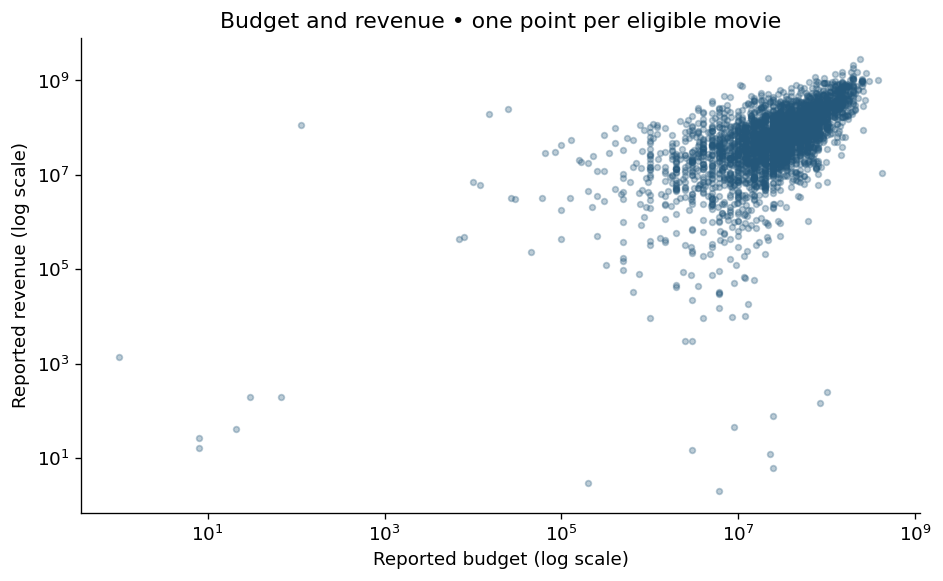

In [6]:
selected = movies.loc[financial & movies['vote_count'].ge(MIN_VOTES)]
pairs=[('vote_average','revenue'),('vote_average','gross_surplus_proxy'),
       ('popularity','revenue'),('popularity','gross_surplus_proxy'),
       ('budget','revenue'),('budget','gross_surplus_proxy'),('budget','popularity')]
associations=[]
for x,y in pairs:
    sample=selected[[x,y]].dropna()
    rho=sample[x].corr(sample[y],method='spearman') if len(sample)>1 and sample[x].nunique()>1 and sample[y].nunique()>1 else np.nan
    associations.append({'x':x,'y':y,'n':len(sample),'spearman_rho':rho})
associations=pd.DataFrame(associations)
display(associations)
associations.to_csv(OUT/'associations.csv',index=False)
fig,ax=plt.subplots(figsize=(8,5))
ax.scatter(selected['budget'],selected['revenue'],s=12,alpha=.3,color=BLUE)
ax.set(xscale='log',yscale='log',xlabel='Reported budget (log scale)',ylabel='Reported revenue (log scale)',title='Budget and revenue • one point per eligible movie')
fig.tight_layout();fig.savefig(OUT/'budget_revenue.png',dpi=160,bbox_inches='tight');plt.show()


### Genre and release year
Small cells are suppressed below five financial observations. The values remain nominal and are not comparable purchasing-power measures across decades.


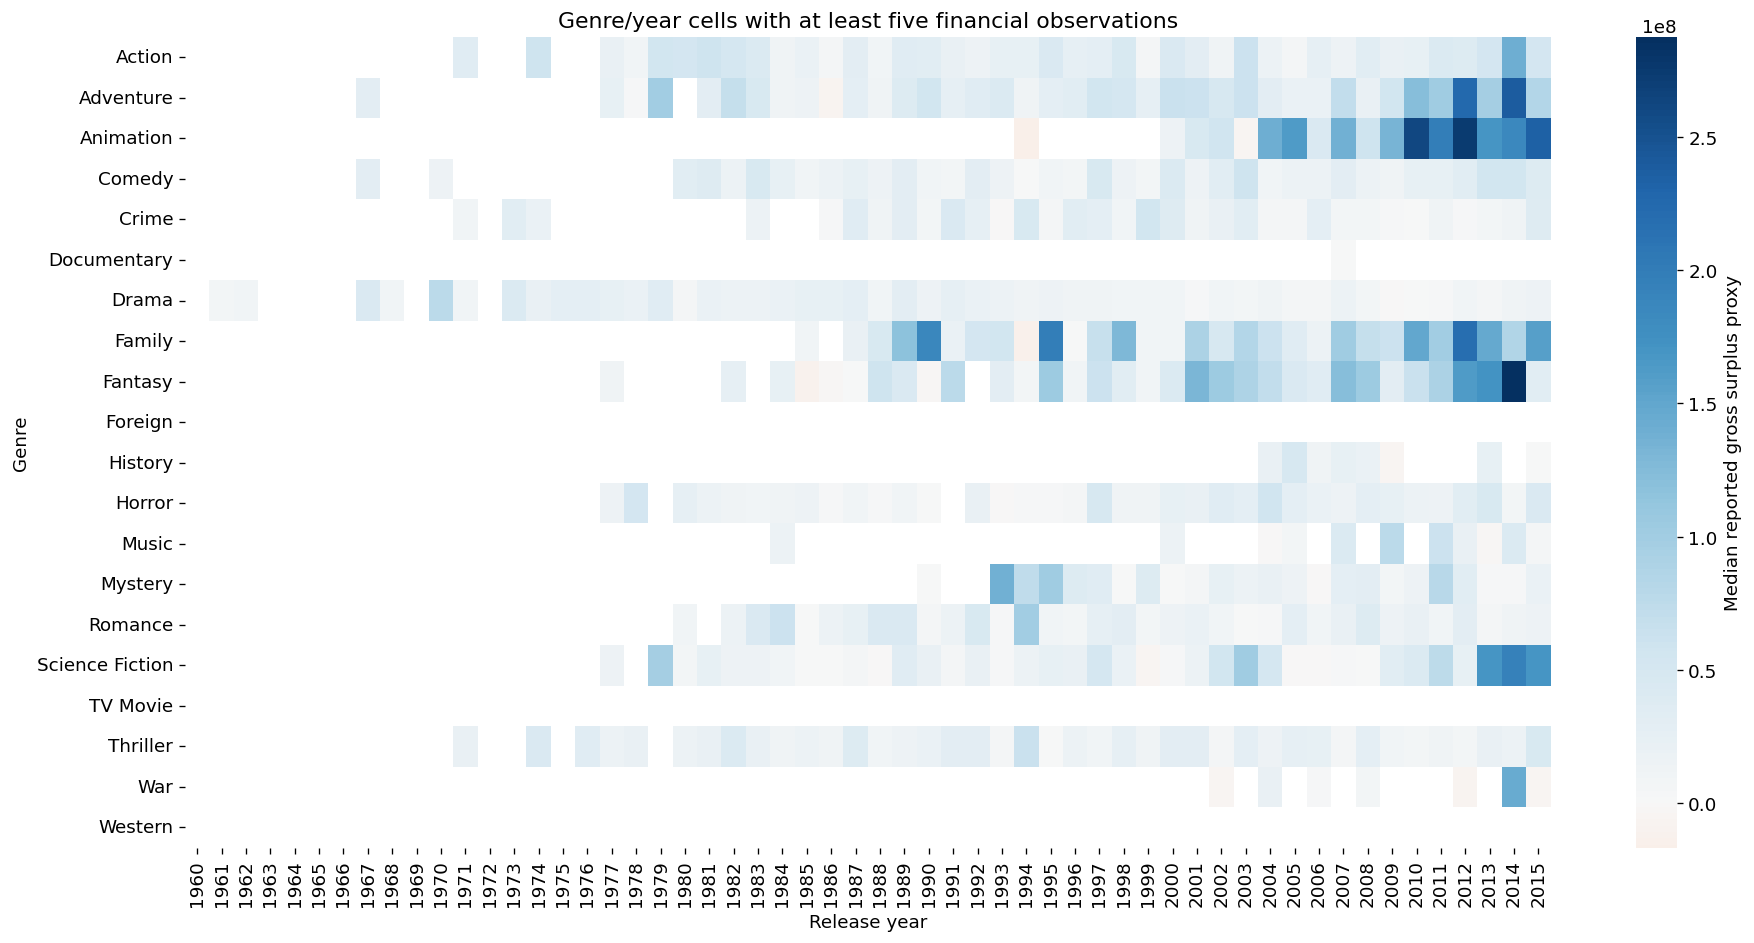

In [7]:
import seaborn as sns
year_stats=genres.groupby(['genre','release_year']).agg(n=('gross_surplus_proxy','count'),median_surplus=('gross_surplus_proxy','median'))
year_stats['median_surplus']=year_stats['median_surplus'].where(year_stats['n'].ge(5))
year_stats.to_csv(OUT/'genre_year_financials.csv')
matrix=year_stats['median_surplus'].unstack()
if matrix.notna().any().any():
    fig,ax=plt.subplots(figsize=(16,8))
    sns.heatmap(matrix,ax=ax,cmap='RdBu',center=0,cbar_kws={'label':'Median reported gross surplus proxy'})
    ax.set(title='Genre/year cells with at least five financial observations',xlabel='Release year',ylabel='Genre')
    fig.tight_layout();fig.savefig(OUT/'genre_year.png',dpi=160,bbox_inches='tight');plt.show()


## Interpretation
Review source coverage, eligible financial sample sizes, and output tables before choosing a genre strategy. Include movie counts and missing-data policy in each conclusion. Do not reuse earlier counts or claim a genre causes higher revenue.

## Attribution
Course-practice notebook submitted by Sharan Kumar Rathod, identified by the author as Alex the Analyst coursework. Confirm the exact lesson, dataset source, and license before publication. Revised logic: stable IDs, modern explode, eligible denominators, financial-data filtering, and cautious interpretation.
